In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    ConfusionMatrixDisplay
)

print("Library berhasil disiapkan!")

Library berhasil disiapkan!


In [2]:
iris = load_iris()

X = pd.DataFrame(
    iris.data,
    columns=iris.feature_names
)

y = pd.Series(
    iris.target,
    name="spesies"
)

df = X.copy()
df["spesies"] = y.map(
    dict(enumerate(iris.target_names))
)

display(df.head(10))

print("Jumlah data:", len(df))
print("Jumlah fitur:", X.shape[1])
print("Jumlah kelas:", y.nunique())
print("\nNama kelas:", list(iris.target_names))

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),spesies
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa
5,5.4,3.9,1.7,0.4,setosa
6,4.6,3.4,1.4,0.3,setosa
7,5.0,3.4,1.5,0.2,setosa
8,4.4,2.9,1.4,0.2,setosa
9,4.9,3.1,1.5,0.1,setosa


Jumlah data: 150
Jumlah fitur: 4
Jumlah kelas: 3

Nama kelas: [np.str_('setosa'), np.str_('versicolor'), np.str_('virginica')]


In [3]:
print("Informasi dataset:")
df.info()

print("\nData kosong:")
display(df.isnull().sum())

print("\nStatistik deskriptif:")
display(X.describe().round(2))

print("\nJumlah data setiap spesies:")
display(df["spesies"].value_counts())

Informasi dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
 4   spesies            150 non-null    object 
dtypes: float64(4), object(1)
memory usage: 6.0+ KB

Data kosong:


,0
sepal length (cm),0
sepal width (cm),0
petal length (cm),0
petal width (cm),0
spesies,0



Statistik deskriptif:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
count,150.00,150.00,150.00,150.00
mean,5.84,3.06,3.76,1.20
std,0.83,0.44,1.77,0.76
min,4.30,2.00,1.00,0.10
25%,5.10,2.80,1.60,0.30
50%,5.80,3.00,4.35,1.30
75%,6.40,3.30,5.10,1.80
max,7.90,4.40,6.90,2.50



Jumlah data setiap spesies:


,count
spesies,
setosa,50
versicolor,50
virginica,50


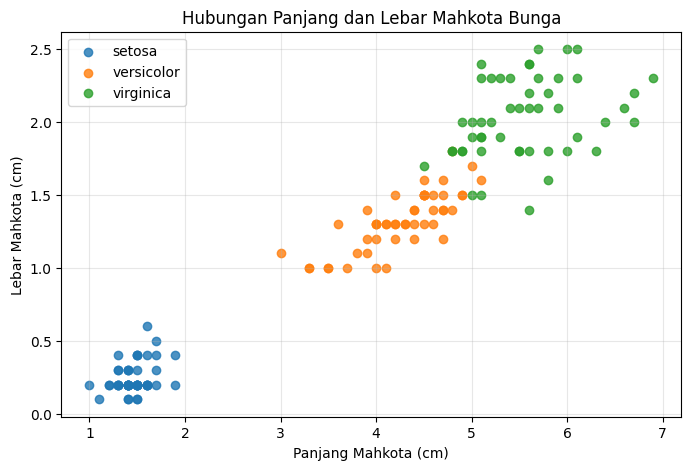

In [4]:
plt.figure(figsize=(8, 5))

for spesies in iris.target_names:
    subset = df[df["spesies"] == spesies]

    plt.scatter(
        subset["petal length (cm)"],
        subset["petal width (cm)"],
        label=spesies,
        alpha=0.8
    )

plt.title("Hubungan Panjang dan Lebar Mahkota Bunga")
plt.xlabel("Panjang Mahkota (cm)")
plt.ylabel("Lebar Mahkota (cm)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Jumlah data training:", len(X_train))
print("Jumlah data testing:", len(X_test))

Jumlah data training: 120
Jumlah data testing: 30


In [6]:
model = DecisionTreeClassifier(
    max_depth=3,
    random_state=42
)

model.fit(X_train, y_train)

print("Model berhasil dilatih!")

Model berhasil dilatih!


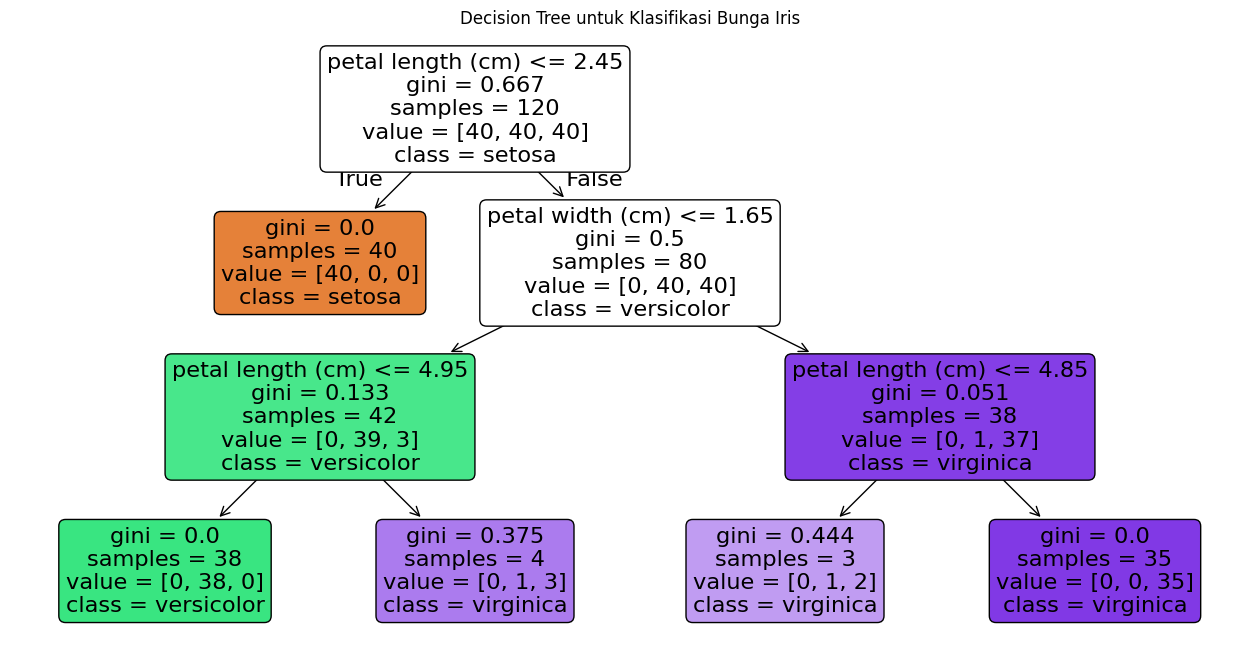

In [7]:
plt.figure(figsize=(16, 8))

plot_tree(
    model,
    feature_names=iris.feature_names,
    class_names=iris.target_names,
    filled=True,
    rounded=True
)

plt.title("Decision Tree untuk Klasifikasi Bunga Iris")
plt.show()

In [8]:
y_pred = model.predict(X_test)

hasil = X_test.copy()
hasil["spesies_asli"] = y_test.map(
    dict(enumerate(iris.target_names))
)
hasil["spesies_prediksi"] = [
    iris.target_names[i] for i in y_pred
]

display(hasil.head(15))

akurasi = accuracy_score(y_test, y_pred)

print(f"Akurasi model: {akurasi * 100:.2f}%")

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),spesies_asli,spesies_prediksi
38,4.4,3.0,1.3,0.2,setosa,setosa
127,6.1,3.0,4.9,1.8,virginica,virginica
57,4.9,2.4,3.3,1.0,versicolor,versicolor
93,5.0,2.3,3.3,1.0,versicolor,versicolor
42,4.4,3.2,1.3,0.2,setosa,setosa
56,6.3,3.3,4.7,1.6,versicolor,versicolor
22,4.6,3.6,1.0,0.2,setosa,setosa
20,5.4,3.4,1.7,0.2,setosa,setosa
147,6.5,3.0,5.2,2.0,virginica,virginica
84,5.4,3.0,4.5,1.5,versicolor,versicolor


Akurasi model: 96.67%


Laporan klasifikasi:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30



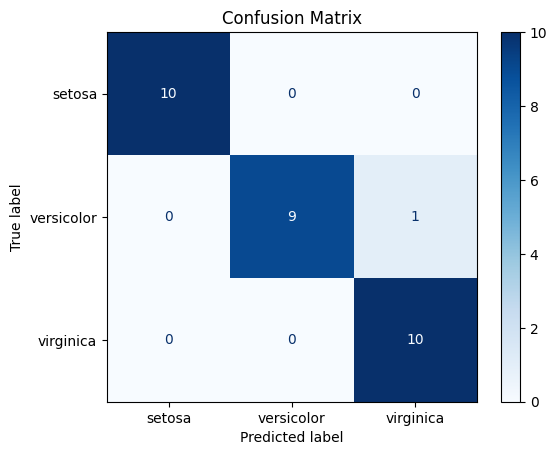

In [9]:
print("Laporan klasifikasi:")
print(
    classification_report(
        y_test,
        y_pred,
        target_names=iris.target_names,
        zero_division=0
    )
)

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=iris.target_names,
    cmap="Blues"
)

plt.title("Confusion Matrix")
plt.show()

In [10]:
bunga_baru = pd.DataFrame(
    [[5.1, 3.5, 1.4, 0.2]],
    columns=iris.feature_names
)

prediksi = model.predict(bunga_baru)[0]
probabilitas = model.predict_proba(bunga_baru)[0]

print("Data bunga baru:")
display(bunga_baru)

print("Hasil prediksi:", iris.target_names[prediksi])

print("\nProbabilitas setiap spesies:")
for nama, peluang in zip(iris.target_names, probabilitas):
    print(f"{nama}: {peluang * 100:.2f}%")

Data bunga baru:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2


Hasil prediksi: setosa

Probabilitas setiap spesies:
setosa: 100.00%
versicolor: 0.00%
virginica: 0.00%


In [11]:
hasil["spesies_asli"] = hasil["spesies_asli"]
hasil.to_csv("webinar4_hasil_prediksi.csv", index=False)

print("Hasil prediksi berhasil disimpan ke webinar4_hasil_prediksi.csv")

Hasil prediksi berhasil disimpan ke webinar4_hasil_prediksi.csv


In [12]:
from google.colab import files

files.download("webinar4_hasil_prediksi.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>